# Klasifikacija slika prirode i grada (CNN)

Cilj je napraviti konvolucijsku neuronsku mrežu koja prepoznaje što je na slici: zgrade, šuma, ledenjak, planina, more ili ulica.
Krenuo sam od jednostavnog modela i postupno ga mijenjao (dropout, dublja mreža, augmentacija, batch normalization)

Dataset: [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification), slike 150x150, 6 klasa.

In [ ]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import kagglehub

## Podaci

In [ ]:
dataset_path = kagglehub.dataset_download("puneet6060/intel-image-classification")

train_dir = os.path.join(dataset_path, "seg_train", "seg_train")
test_dir = os.path.join(dataset_path, "seg_test", "seg_test")

print(train_dir)
print(test_dir)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
/kaggle/input/intel-image-classification/seg_train/seg_train
/kaggle/input/intel-image-classification/seg_test/seg_test


In [ ]:
def count_images_in_directory(directory):
    total = 0
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.lower().endswith(('.jpg', '.png', '.jpeg')):
                total += 1
    return total

print("Ukupan broj slika:")
print("Train:", count_images_in_directory(train_dir))
print("Test :", count_images_in_directory(test_dir))

Ukupan broj slika:
Train: 14034
Test : 3000


Za trening imam oko 14 000 slika, a za test 3 000. Testni skup ne diram do same evaluacije, a za validaciju odvajam 20 % trening slika.

In [ ]:
IMG_SIZE = (150,150)
BATCH_SIZE = 32
EPOCHS = 15
NUM_CLASSES = 6

Radim dvije verzije generatora: jednu bez augmentacije i jednu s augmentacijom (rotacija, zoom, zrcaljenje), da kasnije mogu usporediti razliku.
Testni generator ima `shuffle=False` kako bi redoslijed predikcija odgovarao redoslijedu slika.

In [ ]:
base_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_base = base_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training"
)

val_base = base_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation"
)

Found 11230 images belonging to 6 classes.
Found 2804 images belonging to 6 classes.


In [ ]:
aug_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

train_aug = aug_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training"
)

val_aug = aug_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation"
)

Found 11230 images belonging to 6 classes.
Found 2804 images belonging to 6 classes.


In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 3000 images belonging to 6 classes.


In [ ]:
def plot_history(history, title):
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs_range = range(len(acc))

    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    plt.plot(epochs_range, acc, label="Training Accuracy")
    plt.plot(epochs_range, val_acc, label="Validation Accuracy")
    plt.legend()
    plt.title("Accuracy")

    plt.subplot(1,2,2)
    plt.plot(epochs_range, loss, label="Training Loss")
    plt.plot(epochs_range, val_loss, label="Validation Loss")
    plt.legend()
    plt.title("Loss")

    plt.suptitle(title)
    plt.show()

## Model 1: osnovni CNN

Dva konvolucijska sloja i jedan Dense sloj. Služi kao početna točka s kojom uspoređujem ostale modele.

In [ ]:
model1 = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(150,150,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model1.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model1.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     5,308,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,328,262 (20.33 MB)

 Trainable params: 5,328,262 (20.33 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 215ms/step - accuracy: 0.5828 - loss: 1.1111 - val_accuracy: 0.7047 - val_loss: 0.8069
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 78ms/step - accuracy: 0.7490 - loss: 0.6793 - val_accuracy: 0.7297 - val_loss: 0.7123
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 78ms/step - accuracy: 0.8419 - loss: 0.4435 - val_accuracy: 0.7817 - val_loss: 0.6533
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.9115 - loss: 0.2611 - val_accuracy: 0.7750 - val_loss: 0.7659
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 76ms/step - accuracy: 0.9584 - loss: 0.1345 - val_accuracy: 0.7789 - val_loss: 0.8767
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.9832 - loss: 0.0688 - val_accuracy: 0.7611 - val_loss: 1.0346
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.9840 - loss: 0.0593 - val_accuracy: 0.7603 - val_loss: 1.1046
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.9837 - loss: 0.0601 -

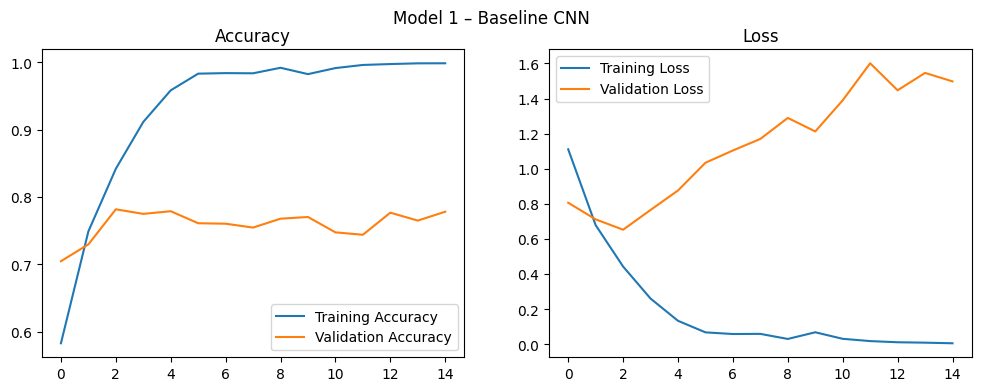

In [ ]:
history1 = model1.fit(
    train_base,
    epochs=EPOCHS,
    validation_data=val_base
)

plot_history(history1, "Model 1 – Baseline CNN")

In [ ]:
test_loss, test_acc = model1.evaluate(test_generator)
print("Model 1 - Test accuracy:", test_acc)


94/94 ━━━━━━━━━━━━━━━━━━━━ 17s 178ms/step - accuracy: 0.7757 - loss: 1.4742
Model 1 - Test accuracy: 0.7756666541099548


**Rezultat:** 77,6 % točnosti na testu.

Model jako brzo pretrenirava (overfitting). Točnost na treningu dođe skoro do 100 %, a validacija stane na oko 78 % već u 3. epohi i dalje ne raste.
Validacijski loss je najmanji u 3. epohi (0,65), a nakon toga raste do oko 1,5, što znači da model sve više uči napamet trening slike.
Veći dio od 5,3 milijuna parametara nalazi se u Dense sloju nakon `Flatten` (82 944 x 64), pa model ima puno prostora za pamćenje.

## Model 1 + Dropout

Isti model, samo s `Dropout(0.5)` prije izlaznog sloja, da vidim koliko to smanjuje overfitting.

In [ ]:
model1_imp = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(150,150,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model1_imp.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 32s 81ms/step - accuracy: 0.5346 - loss: 1.2073 - val_accuracy: 0.6954 - val_loss: 0.8599
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.6986 - loss: 0.8331 - val_accuracy: 0.7578 - val_loss: 0.6652
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.7608 - loss: 0.6623 - val_accuracy: 0.7842 - val_loss: 0.6207
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 76ms/step - accuracy: 0.8083 - loss: 0.5353 - val_accuracy: 0.7924 - val_loss: 0.6022
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 80ms/step - accuracy: 0.8462 - loss: 0.4295 - val_accuracy: 0.7789 - val_loss: 0.6788
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.8805 - loss: 0.3394 - val_accuracy: 0.8006 - val_loss: 0.6155
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.9024 - loss: 0.2819 - val_accuracy: 0.8031 - val_loss: 0.6349
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 32s 91ms/step - accuracy: 0.9199 - loss: 0.2262 - 

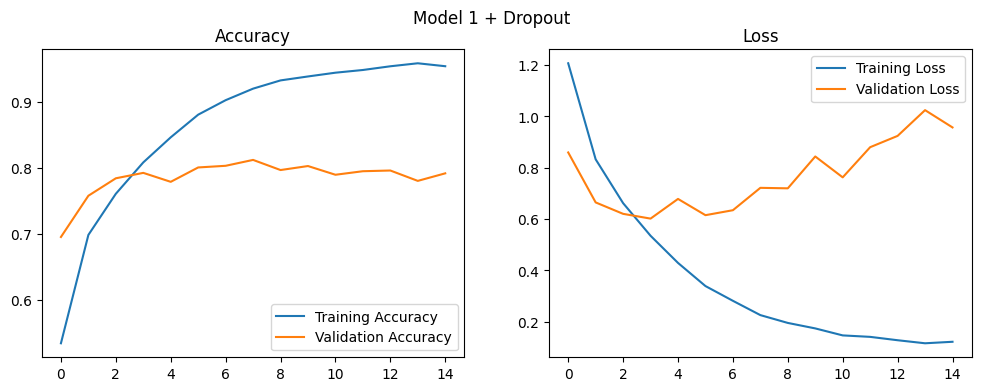

In [ ]:
history1_imp = model1_imp.fit(
    train_base,
    epochs=EPOCHS,
    validation_data=val_base
)

plot_history(history1_imp, "Model 1 + Dropout")

In [ ]:
test_loss, test_acc = model1_imp.evaluate(test_generator)
print("Model 1 + Dropout - Test accuracy:", test_acc)

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.7983 - loss: 1.0201
Model 1 + Dropout - Test accuracy: 0.7983333468437195


**Rezultat:** 79,8 % na testu, oko 2% bolje od Modela 1.





Dropout je usporio overfitting, ali ga nije zaustavio. Trening točnost raste sporije i na kraju je oko 95 % (kod Modela 1 skoro 100 %),
a validacija dođe do 81 % u 8. epohi. Validacijski loss je najmanji u 4. epohi (0,60), a poslije opet raste do oko 1,0,
iako puno sporije nego kod Modela 1 (1,5).

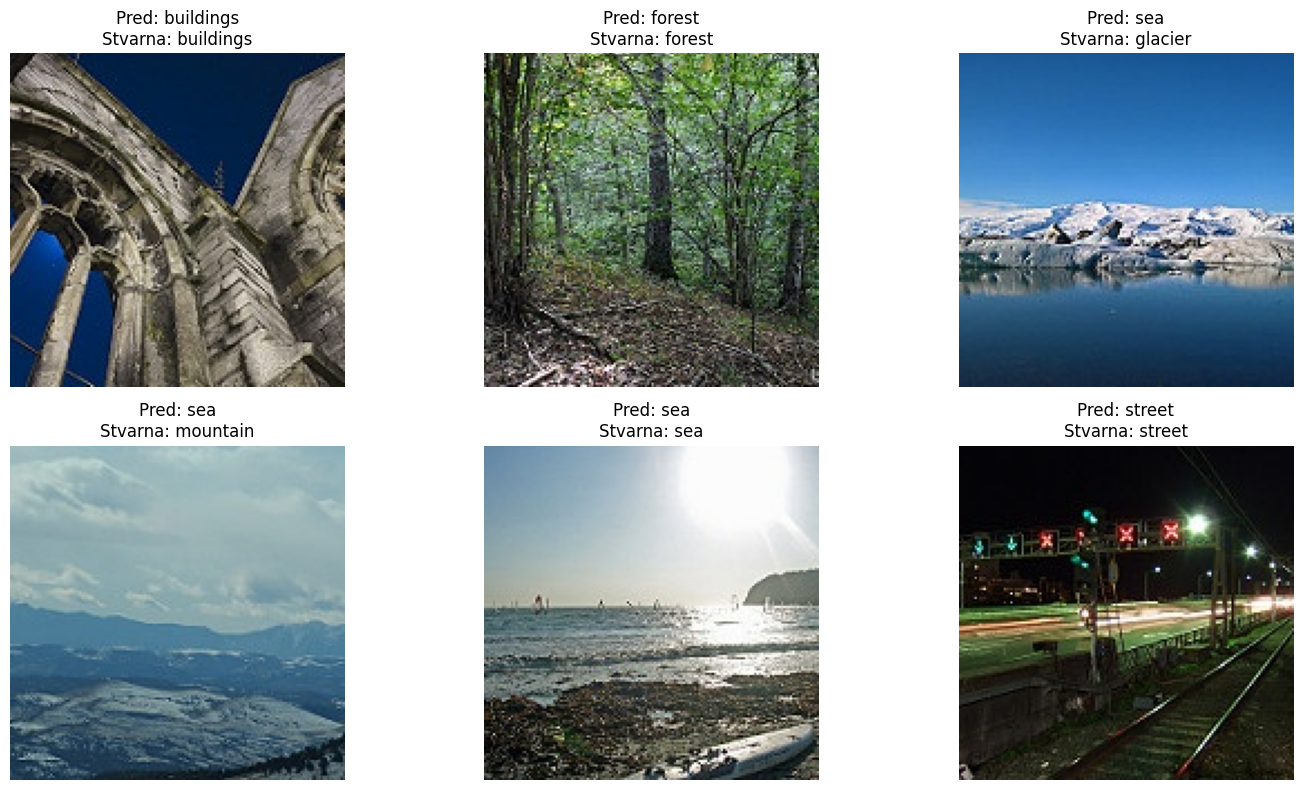

In [ ]:
class_names = sorted(os.listdir(train_dir))


def show_predictions(model):
    # jedna nasumična slika iz testnog skupa za svaku klasu
    plt.figure(figsize=(15, 8))
    for i, class_name in enumerate(class_names):
        class_folder = os.path.join(test_dir, class_name)
        img_path = os.path.join(class_folder, random.choice(os.listdir(class_folder)))

        img = image.load_img(img_path, target_size=IMG_SIZE)
        img_array = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)

        pred = model.predict(img_array, verbose=0)
        pred_class_name = class_names[np.argmax(pred, axis=1)[0]]

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Pred: {pred_class_name}\nStvarna: {class_name}", fontsize=12)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(model1)

## Model 2: dublji CNN

Dodao sam treći konvolucijski sloj (128 filtera) i veći Dense sloj. Svaki dodatni MaxPooling smanjuje sliku prije `Flatten`, pa model ima manje parametara u Dense sloju.

In [ ]:
model2 = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(150,150,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model2.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 39s 92ms/step - accuracy: 0.6159 - loss: 0.9834 - val_accuracy: 0.7443 - val_loss: 0.7230
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 76ms/step - accuracy: 0.7631 - loss: 0.6504 - val_accuracy: 0.7964 - val_loss: 0.6017
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.8204 - loss: 0.5017 - val_accuracy: 0.8099 - val_loss: 0.5501
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 34s 96ms/step - accuracy: 0.8654 - loss: 0.3825 - val_accuracy: 0.8228 - val_loss: 0.5232
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.9121 - loss: 0.2591 - val_accuracy: 0.8149 - val_loss: 0.5907
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.9424 - loss: 0.1639 - val_accuracy: 0.8085 - val_loss: 0.7464
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 26s 75ms/step - accuracy: 0.9689 - loss: 0.0999 - val_accuracy: 0.7803 - val_loss: 0.9580
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.9785 - loss: 0.0699 - 

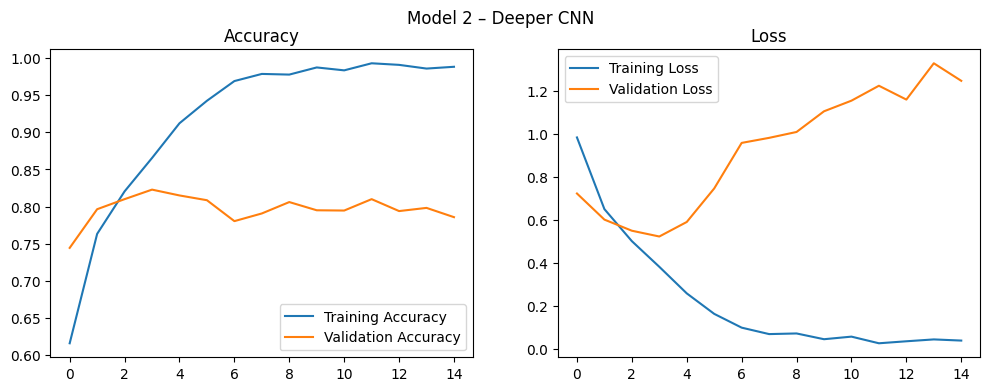

In [ ]:
history2 = model2.fit(
    train_base,
    epochs=EPOCHS,
    validation_data=val_base
)

plot_history(history2, "Model 2 – Deeper CNN")

In [ ]:
test_loss, test_acc = model2.evaluate(test_generator)
print("Model 2 - Test accuracy:", test_acc)


94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.7930 - loss: 1.2802
Model 2 - Test accuracy: 0.7929999828338623


**Rezultat:** 79,3 % na testu, bolje od Modela 1, ali otprilike isto kao Model 1 + Dropout.

Dublja mreža brže uči korisne značajke (validacija 81 % već u 3. epohi, najbolje 82 % u 4. epohi), ali overfitting je isti kao kod Modela 1:
trening ide na 99 %, a validacijski loss raste s 0,52 na oko 1,25. Sama dubina ne rješava problem, a dropout je na manjem modelu dao skoro isti učinak.

## Model 2 + augmentacija

Isti Model 2 sam nastavio trenirati još 15 epoha, ali sad na augmentiranim slikama (rotacija, zoom, zrcaljenje).

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 110s 314ms/step - accuracy: 0.7736 - loss: 0.6596 - val_accuracy: 0.7899 - val_loss: 0.5904
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 143s 317ms/step - accuracy: 0.8172 - loss: 0.5134 - val_accuracy: 0.8249 - val_loss: 0.5136
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 108s 308ms/step - accuracy: 0.8328 - loss: 0.4651 - val_accuracy: 0.8242 - val_loss: 0.5184
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 109s 310ms/step - accuracy: 0.8417 - loss: 0.4283 - val_accuracy: 0.8042 - val_loss: 0.5534
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 105s 300ms/step - accuracy: 0.8501 - loss: 0.4076 - val_accuracy: 0.8192 - val_loss: 0.5312
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 109s 309ms/step - accuracy: 0.8633 - loss: 0.3792 - val_accuracy: 0.8277 - val_loss: 0.5056
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 108s 308ms/step - accuracy: 0.8703 - loss: 0.3580 - val_accuracy: 0.8249 - val_loss: 0.4892
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 109s 310ms/step - accuracy: 0.8760 -

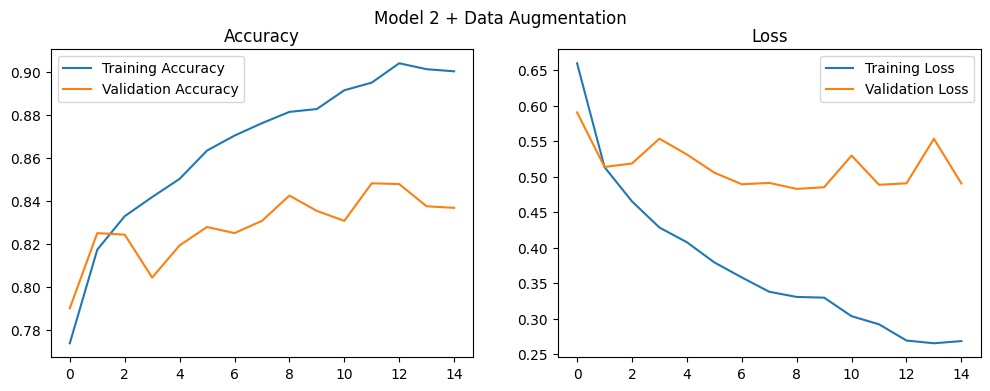

In [ ]:
history2_imp = model2.fit(
    train_aug,
    epochs=EPOCHS,
    validation_data=val_aug
)

plot_history(history2_imp, "Model 2 + Data Augmentation")

In [ ]:
test_loss, test_acc = model2.evaluate(test_generator)
print("Model 2 - Test accuracy:", test_acc)

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.8430 - loss: 0.5099
Model 2 - Test accuracy: 0.8429999947547913


**Rezultat:** 84,3 % na testu, najbolji rezultat u ovom notebooku.

Augmentacija je napravila najveću razliku. Trening točnost je pala s 99 % na oko 90 %, a validacija je porasla na 83 do 85 %.
Validacijski loss ostaje stabilan oko 0,48 do 0,55 umjesto da raste, što znači da je overfitting uglavnom nestao.
Budući da model u svakoj epohi vidi malo drugačije verzije slika, teže ih uči napamet.

Napomena: ovaj model nije treniran od nule, nego je nastavio od Modela 2, pa je ukupno imao 30 epoha. Ipak, dodatno treniranje bez augmentacije
samo je pogoršavalo overfitting kod Modela 2, pa poboljšanje pripisujem augmentaciji.

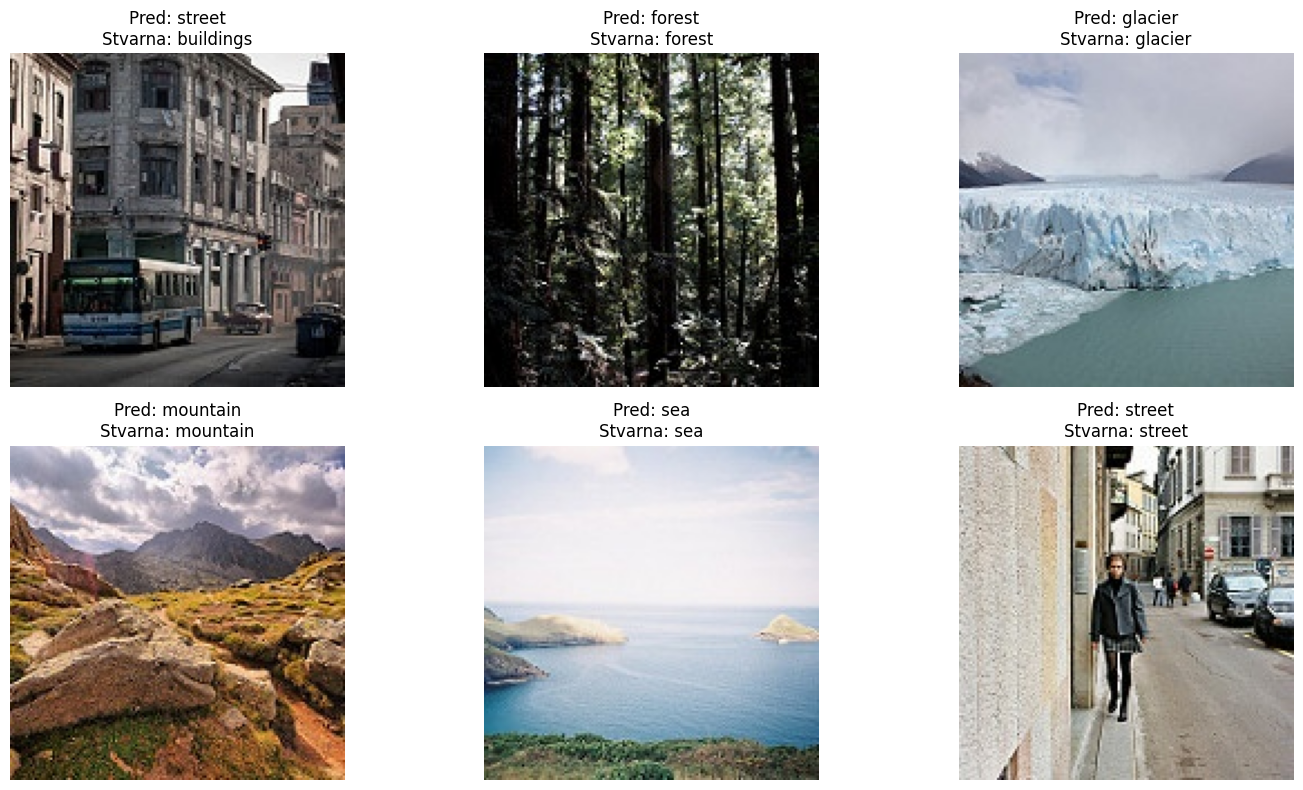

In [ ]:
show_predictions(model2)

## Model 3: Batch Normalization

Model 2 s `BatchNormalization` nakon svakog konvolucijskog sloja, treniran od nule na augmentiranim podacima.

In [ ]:
model3 = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(150,150,3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model3.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 120s 322ms/step - accuracy: 0.5743 - loss: 1.5590 - val_accuracy: 0.5000 - val_loss: 1.6862
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 107s 306ms/step - accuracy: 0.6977 - loss: 0.8539 - val_accuracy: 0.5756 - val_loss: 1.2729
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 106s 302ms/step - accuracy: 0.7462 - loss: 0.7113 - val_accuracy: 0.7457 - val_loss: 0.6930
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 106s 303ms/step - accuracy: 0.7687 - loss: 0.6415 - val_accuracy: 0.5952 - val_loss: 1.1228
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 107s 304ms/step - accuracy: 0.7859 - loss: 0.5931 - val_accuracy: 0.7150 - val_loss: 0.8459
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 107s 304ms/step - accuracy: 0.8058 - loss: 0.5491 - val_accuracy: 0.5303 - val_loss: 1.6056
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 108s 307ms/step - accuracy: 0.8142 - loss: 0.5259 - val_accuracy: 0.7439 - val_loss: 0.7496
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 106s 303ms/step - accuracy: 0.8288 -

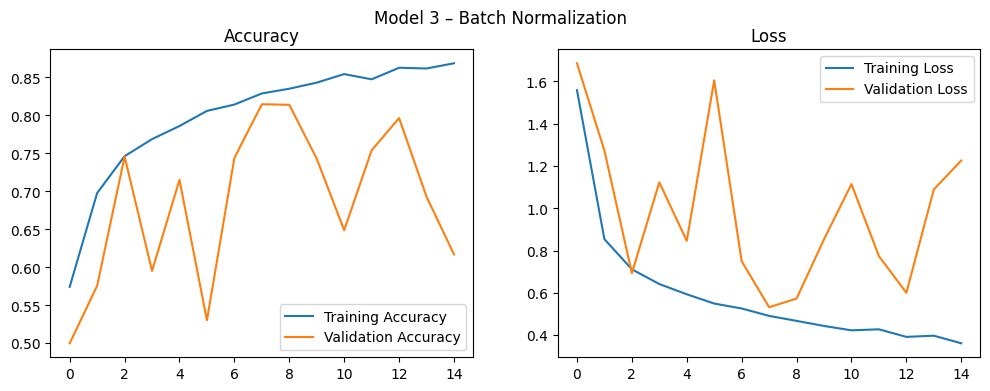

In [ ]:
history3 = model3.fit(
    train_aug,
    epochs=EPOCHS,
    validation_data=val_aug
)

plot_history(history3, "Model 3 – Batch Normalization")


In [ ]:
test_loss, test_acc = model3.evaluate(test_generator)
print("Model 3 - Test accuracy:", test_acc)

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.6347 - loss: 1.1928
Model 3 - Test accuracy: 0.6346666812896729


**Rezultat:** 63,5 % na testu, najlošiji rezultat u notebooku.

Validacija je kod ovog modela jako nestabilna i skače između 50 % i 81 % iz epohe u epohu. Najbolja je bila 81 % u 8. epohi,
ali treniranje je završilo na lošoj epohi (62 %), a test mjeri model iz zadnje epohe.



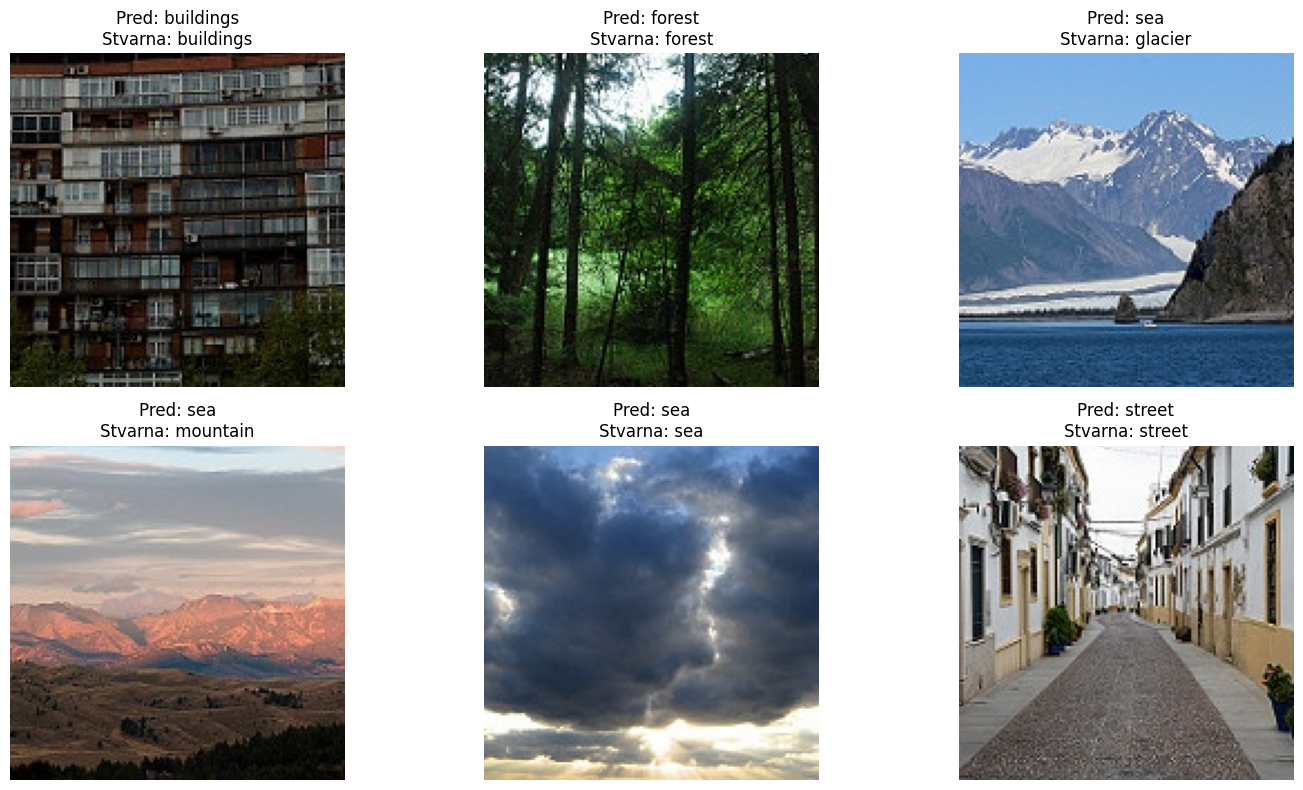

In [ ]:
show_predictions(model3)

## Usporedba i zaključak

| Model | Test točnost |
|---|---|
| Model 1 (osnovni CNN) | 77,6 % |
| Model 1 + Dropout | 79,8 % |
| Model 2 (dublji CNN) | 79,3 % |
| Model 2 + augmentacija | **84,3 %** |
| Model 3 (Batch Normalization + augmentacija) | 63,5 % |

Glavni problem svih modela bio je overfitting, a ne premala mreža. Dublji model i dropout su svaki pomogli za oko 2%
(77,6 % na 79,3 % i 79,8 %), dok je augmentacija podataka donijela najveći skok (79,3 % na 84,3 %).

Model 3 pokazuje koliko rezultat ovisi o tome na kojoj epohi treniranje stane: u najboljoj epohi je imao 81 % na validaciji,
a na testu samo 63,5 %, jer je zadnja epoha bila loša.

Kod svih modela bez augmentacije validacijski loss je najmanji već u 3. ili 4. epohi i onda raste, pa je 15 epoha bez ranog zaustavljanja previše.



